## Current scope: real PDFs and a real LLM

The project has returned to its original extension: visibility-diff plus a transformer classifier protecting an actual LLM screener on real PDF résumés. Start with [Real PDF LLM Defence — Colab](colab/Real_PDF_LLM_Defence_Colab.ipynb), and optionally [T4 classifier training](colab/Train_Transformer_Classifier_T4.ipynb).

The earlier text-classification results and paper are a **pilot**. They are not results for the real-PDF/LLM extension. The new experiment must be run in Colab before its M4–M6 results and final paper can be completed. This notice supersedes earlier statements that narrowed the project to text-only detection.

# M4 — Controlled experiments

Run `python experiment.py` from the repository root to reproduce training. This notebook reads the recorded run and checks its provenance without retraining. Full text, labels, group IDs and predictions are exported in [results/](results/).

In [1]:
import json, hashlib
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
r = json.loads(Path('results/run.json').read_text())
for name, expected in r['input_sha256'].items():
    assert hashlib.sha256(Path(name).read_bytes()).hexdigest() == expected, name
print('Input hashes verified; run:', r['started_utc'])
print('Environment:', r['environment'])
print('Source sentences:', r['split_sources'], 'Expanded rows:', r['split_rows'])

Input hashes verified; run: 2026-11-25T02:52:04.773189+00:00
Environment: {'python': '3.14.0', 'sklearn': '1.9.1', 'numpy': '2.5.5'}
Source sentences: {'train': 32, 'validation': 16, 'test': 32} Expanded rows: {'train': 96, 'validation': 48, 'test': 96}


## Baseline and experimental configurations

**Baseline:** seven fixed keyword phrases from the initial M2 detector intent; substring matching, case-insensitive. This is the lexical component only, not the complete ResumeShield system.

**Experimental:** normalize zero-width/confusable characters, character TF-IDF (3–5 characters within words), logistic regression C=1, balanced class weights, liblinear, seed 42, max_iter=1000. There is no hyperparameter search. Threshold candidates are 0.3, 0.5, 0.7; choose best validation F1 subject to FPR≤0.10. The exact fallback and tie rules are in the protocol.

**Metrics:** precision=TP/(TP+FP); recall=TP/(TP+FN); F1=2PR/(P+R); FPR=FP/(FP+TN). Counts are shown so denominators remain clear. For absent classes, the code returns zero; such per-family metrics are not meaningful. Detection recall is not attack success rate or hiring utility.

In [2]:
display(pd.DataFrame(r['metrics']).T)
print('Validation-selected thresholds:', r['thresholds'])
display(pd.DataFrame([{'model': name, **v} for name, values in r['validation'].items() for v in values]))

,n,tp,fp,fn,tn,precision,recall,f1,fpr
keywords,96.0,0.0,4.0,48.0,44.0,0.000000,0.000000,0.000000,0.083333
normalized_keywords,96.0,0.0,12.0,48.0,36.0,0.000000,0.000000,0.000000,0.250000
normalized_char_lr,96.0,45.0,9.0,3.0,39.0,0.833333,0.937500,0.882353,0.187500
raw_char_lr,96.0,44.0,10.0,4.0,38.0,0.814815,0.916667,0.862745,0.208333
normalized_word_lr,96.0,12.0,0.0,36.0,48.0,1.000000,0.250000,0.400000,0.000000


Validation-selected thresholds: {'normalized_char_lr': 0.5, 'raw_char_lr': 0.5, 'normalized_word_lr': 0.7}


,model,threshold,n,tp,fp,fn,tn,precision,recall,f1,fpr
0,normalized_char_lr,0.3,48,24,18,0,6,0.571429,1.000,0.727273,0.750
1,normalized_char_lr,0.5,48,24,0,0,24,1.000000,1.000,1.000000,0.000
2,normalized_char_lr,0.7,48,12,0,12,24,1.000000,0.500,0.666667,0.000
3,raw_char_lr,0.3,48,24,24,0,0,0.500000,1.000,0.666667,1.000
4,raw_char_lr,0.5,48,24,0,0,24,1.000000,1.000,1.000000,0.000
5,raw_char_lr,0.7,48,0,0,24,24,0.000000,0.000,0.000000,0.000
6,normalized_word_lr,0.3,48,24,24,0,0,0.500000,1.000,0.666667,1.000
7,normalized_word_lr,0.5,48,24,3,0,21,0.888889,1.000,0.941176,0.125
8,normalized_word_lr,0.7,48,15,0,9,24,1.000000,0.625,0.769231,0.000


## Predicted versus actual

Before training: recall improvement ≥0.20 and experimental FPR ≤0.10. Both must pass. Failure of either condition means the hypothesis is not supported on this benchmark.

In [3]:
print('Recall gain:', r['recall_gain'])
print('Experimental FPR:', r['metrics']['normalized_char_lr']['fpr'])
print('Hypothesis supported:', r['hypothesis_supported'])
print('Descriptive family-bootstrap 95% interval for recall gain:', r['family_bootstrap_95_interval'])
assert r['hypothesis_supported'] == (r['recall_gain'] >= .2 and r['metrics']['normalized_char_lr']['fpr'] <= .1)

Recall gain: 0.9375
Experimental FPR: 0.1875
Hypothesis supported: False
Descriptive family-bootstrap 95% interval for recall gain: [0.8125, 1.0]


## Ablation study

Removing normalization changes only preprocessing. Replacing character with word features tests representation under the same threshold-selection rule. Normalized keywords isolate normalization without learning. These are paired comparisons on identical test rows. The character and raw-character models select 0.5; the word model selects 0.7. Consequently, word-model recall reflects both representation and its validation-selected operating point.

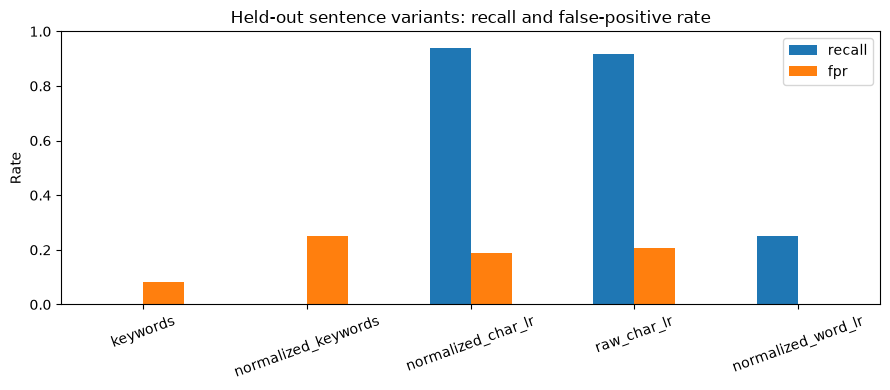

,n,tp,fp,fn,tn,precision,recall,f1,fpr
keywords,32.0,0.0,4.0,16.0,12.0,0.000000,0.0000,0.000000,0.2500
normalized_keywords,32.0,0.0,4.0,16.0,12.0,0.000000,0.0000,0.000000,0.2500
normalized_char_lr,32.0,15.0,3.0,1.0,13.0,0.833333,0.9375,0.882353,0.1875
raw_char_lr,32.0,15.0,3.0,1.0,13.0,0.833333,0.9375,0.882353,0.1875
normalized_word_lr,32.0,4.0,0.0,12.0,16.0,1.000000,0.2500,0.400000,0.0000


In [4]:
table = pd.DataFrame(r['metrics']).T
ax = table[['recall', 'fpr']].plot.bar(figsize=(9,4), ylim=(0,1), rot=20)
ax.set_ylabel('Rate')
ax.set_title('Held-out sentence variants: recall and false-positive rate')
plt.tight_layout()
plt.show()
display(pd.DataFrame(r['original_only']).T)

## Interpretation

The primary model gains 93.75 percentage points in recall but fails the FPR requirement (18.75%). Removing normalization decreases recall by 2.08 points and increases FPR by 2.08 points; this is only one test row each. The word model has 25% recall and no false positives at its selected threshold. Normalized keywords still miss every held-out attack and flag more benign quotations.

Original-only results show the normalized detector catches 15/16 attacks and flags 3/16 benign sentences. The raw keyword baseline flags 4/16 clean originals (25%); its lower expanded-set FPR of 8.33% occurs because obfuscation hides the quoted keywords. This is not genuine semantic discrimination. The test deliberately stresses phrases outside the keyword list, so baseline failure does not estimate real-world baseline performance. Bootstrap resampling uses four attack families rather than 48 independent rows; the interval is descriptive and cannot establish population robustness.